In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from desmin_reconstruction.analysis.ripley import (
    ripley_H_from_L,
    ripley_K,
    ripley_L_from_K,
)
from desmin_reconstruction.preprocessing.bbox import BoundingSquare, filter_bounded
from desmin_reconstruction.preprocessing.storm import align_patch
from tqdm import tqdm
import csv
from dataclasses import dataclass
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from desmin_reconstruction.plotting import save_panel
from desmin_reconstruction.plotting.renderings import (
    render_pointcloud,
)
from IPython.display import display, SVG
from matplotlib.offsetbox import AnnotationBbox, HPacker, TextArea
from matplotlib.patches import Rectangle
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
import numpy as np

COLOR_DICT = {
    "desmin": "#CC3311",
    "actin": "#0077BB",
    "actinin": "#009988",
    "myosin": "#BBBBBB",
}

COLOR_DICT = {
    "desmin":"#CC3311", "actin":"#0077BB",
    "actinin":"#009988", "myosin":"#BBBBBB",
}
LABEL_DICT = {
    "desmin":"Desmin", "actin":"Actin",
    "actinin":"α-actinin", "alpha_actinin":"α-actinin", "myosin":"Myosin",
}
LINESTYLE_DICT = {
    "desmin":"-", "actin":"-.", "actinin":"--", "alpha_actinin":"--", "myosin":":",
}


datadir = Path("../../data/")

In [2]:
def load_ripley_npz(path, *, proteins=None):
    """Return (r, curves), with curves[protein][function] = (mean, SD).

    Each array must be a finite 1D array with the same shape as r. Radii must
    be nonnegative and strictly increasing; SDs must be nonnegative.
    proteins=None discovers species from K_<protein> keys, placing known
    proteins in the designated palette order. Pass a tuple to select/reorder.
    """
    with np.load(path, allow_pickle=False) as data:
        if "r" not in data:
            raise ValueError("NPZ is missing the radius array 'r'.")
        r = np.asarray(data["r"], dtype=float)
        if (r.ndim != 1 or r.size < 2 or not np.isfinite(r).all()
                or np.any(r<0) or np.any(np.diff(r)<=0)):
            raise ValueError("r must be finite, nonnegative, 1D, and strictly increasing.")
        if proteins is None:
            available = [key[2:] for key in data.files
                         if key.startswith("K_") and not key.startswith("K_err_")]
            preferred = ("desmin","actin","actinin","alpha_actinin","myosin")
            proteins = tuple([p for p in preferred if p in available]
                             + [p for p in available if p not in preferred])
        else:
            proteins = tuple(proteins)
        if not proteins or len(set(proteins)) != len(proteins):
            raise ValueError("Select at least one protein, with no duplicate names.")
        curves = {}
        for protein in proteins:
            curves[protein] = {}
            for function in ("K","L","H"):
                keys = (f"{function}_{protein}", f"{function}_err_{protein}")
                missing = [key for key in keys if key not in data]
                if missing:
                    raise ValueError(f"NPZ is missing: {', '.join(missing)}.")
                mean,sd = [np.asarray(data[key],dtype=float) for key in keys]
                if any(v.shape != r.shape or not np.isfinite(v).all() for v in (mean,sd)):
                    raise ValueError(f"{function}/{protein}: mean and SD must be finite and match r.shape.")
                if np.any(sd<0):
                    raise ValueError(f"{function}/{protein}: SD must be nonnegative.")
                curves[protein][function] = (mean,sd)
    return r,curves


def plot_ripley_functions(
    npz_path=None,
    *,
    proteins=None,
    series_sources=None,
    figsize=(9,3.5),
    colors=None,
    labels=None,
    linestyles=None,
    line_width=2.2,
    band_alpha=0.14,
    band_edgewidth=0.0,
    title_fontsize=13,
    label_fontsize=12,
    tick_fontsize=10,
    legend_fontsize=10,
    annotation_fontsize=10,
    font_family="DejaVu Sans",
    spatial_dimension=None,
    xlim=None,
    ylims=None,
    peak_protein="desmin",
    peak_text_position=(0.97,0.08),
    peak_decimals=3,
):
    """Return (fig, axes, info), plotting the stored means with +/-1 SD bands.

    Two input modes share the same renderer:
      1. npz_path with optional proteins: the original single-file interface.
      2. series_sources={series_id: (npz_path, protein_key)}: select one saved
         protein curve per source. Each series retains its own radius grid;
         curves are not interpolated, combined, or re-averaged. In this mode,
         colors/labels/linestyles are keyed by series_id, and peak_protein
         selects a series_id (use None for no peak annotation).
    Provide exactly one input mode. Source order sets the legend/drawing order.

    Uses the designated colors and distinct line styles. A shared legend above
    the panels includes an SD-band key. Myosin's light-gray line receives a
    thin dark outline so its color remains visible on a white background.
    In multi-source mode colors inherit each selected protein's assigned color.
    Repeated selections of the same protein get different default line styles.
    band_edgewidth>0 adds thin mean+SD/mean-SD boundary lines in the series'
    line style, useful when comparing two bands with the same color.

    spatial_dimension=2 or 3 adds appropriate units to K (um^2 or um^3).
    None leaves K's units unspecified because dimension is not stored in the
    supplied NPZ schema. Standard Ripley L and H have distance units (um).
    No CSR K baseline is inferred or added. H=0 is shown as a reference line.

    xlim optionally sets a shared (xmin,xmax); ylims is a dict such as
    {'K':(0,3.2), 'L':(0,1), 'H':(-0.1,0.65)}. Automatic limits include the
    complete SD bands, including any negative lower endpoints.

    peak_protein='desmin' marks the sampled maximum of its saved mean H over
    the FULL radius grid, using np.argmax exactly as in the original code.
    No interpolation or uncertainty on the peak location is inferred. Set
    peak_protein=None to omit it. peak_text_position is an axes-fraction pair.
    Annotation is omitted when the peak lies outside explicit view limits.
    """
    if series_sources is None:
        if npz_path is None:
            raise ValueError("Supply npz_path or series_sources.")
        r,curves = load_ripley_npz(npz_path,proteins=proteins)
        radii = {p:r for p in curves}
        source_proteins = {p:p for p in curves}
        sources = {p:{"path":str(npz_path),"protein":p} for p in curves}
        source_labels = {}
    else:
        if npz_path is not None or proteins is not None:
            raise ValueError("series_sources replaces npz_path/proteins; do not supply both modes.")
        if not series_sources:
            raise ValueError("series_sources must contain at least one named series.")
        curves,radii,source_proteins,sources = {},{},{},{}
        for series_id,(path,protein_key) in series_sources.items():
            r,loaded = load_ripley_npz(path,proteins=(protein_key,))
            radii[series_id],curves[series_id] = r,loaded[protein_key]
            source_proteins[series_id] = protein_key
            sources[series_id] = {"path":str(path),"protein":protein_key}
        source_labels = {key:key.replace("_"," ") for key in curves}
    proteins = tuple(curves)
    palette = {**COLOR_DICT, **(colors or {})}
    palette.setdefault("alpha_actinin",palette["actinin"])
    inherited = {key:palette[p] for key,p in source_proteins.items() if p in palette}
    colors = {**inherited, **(colors or {})}
    labels = {**LABEL_DICT, **source_labels, **(labels or {})}
    styles,seen = {},{}
    repeated_styles = ("-","--","-.",":")
    for key,protein in source_proteins.items():
        occurrence = seen.get(protein,0)
        repeated = sum(p==protein for p in source_proteins.values())>1
        styles[key] = (repeated_styles[occurrence % len(repeated_styles)] if repeated
                       else LINESTYLE_DICT.get(protein,"-"))
        seen[protein] = occurrence+1
    styles.update(linestyles or {})
    missing_colors = [p for p in proteins if p not in colors]
    if missing_colors:
        raise ValueError(f"Supply colors for these proteins: {missing_colors}.")
    if spatial_dimension not in (None,2,3):
        raise ValueError("spatial_dimension must be 2, 3, or None.")
    if peak_protein is not None and peak_protein not in curves:
        raise ValueError("peak_protein is not plotted; select a plotted protein or use None.")
    if not np.isfinite(band_alpha) or not 0<=band_alpha<=1:
        raise ValueError("band_alpha must be between 0 and 1.")
    if not np.isfinite(band_edgewidth) or band_edgewidth < 0:
        raise ValueError("band_edgewidth must be nonnegative.")
    xlim = (min(r[0] for r in radii.values()),max(r[-1] for r in radii.values())) if xlim is None else tuple(xlim)
    if len(xlim)!=2 or not np.isfinite(xlim).all() or xlim[0]>=xlim[1]:
        raise ValueError("xlim must contain two increasing finite values.")
    ylims = ylims or {}
    info = {"proteins":proteins,"peak_protein":peak_protein,"r_star":None,
            "peak_index":None,"H_at_r_star":None,"peak_is_endpoint":None,
            "spatial_dimension":spatial_dimension,"sources":sources,
            "series_ids":proteins}

    with plt.style.context("default"),mpl.rc_context({"font.family":font_family}):
        fig,axes = plt.subplots(1,3,figsize=figsize,sharex=True,
                                layout="constrained",facecolor="white")
        legend_lines = []
        try:
            for ax,function in zip(axes,("K","L","H")):
                # All bands first, then all mean lines, so no band tints a line.
                for protein in proteins:
                    r = radii[protein]
                    mean,sd = curves[protein][function]
                    ax.fill_between(r,mean-sd,mean+sd,color=colors[protein],
                                    alpha=band_alpha,linewidth=0,edgecolor="none",zorder=1)
                    if band_edgewidth > 0:
                        for boundary in (mean-sd,mean+sd):
                            ax.plot(r,boundary,color=colors[protein],
                                    linestyle=styles[protein],linewidth=band_edgewidth,
                                    alpha=0.45,zorder=2,label="_nolegend_")
                for protein in proteins:
                    r = radii[protein]
                    mean,_ = curves[protein][function]
                    line, = ax.plot(r,mean,color=colors[protein],
                                    linestyle=styles.get(protein,"-"),linewidth=line_width,
                                    alpha=1.0,label=labels.get(protein,protein),zorder=3)
                    if source_proteins[protein] == "myosin":
                        line.set_path_effects([
                            pe.Stroke(linewidth=line_width+0.8,foreground="#555555"),
                            pe.Normal(),
                        ])
                    if function == "K":
                        legend_lines.append(line)
                ax.spines[["top","right"]].set_visible(False)
                ax.spines[["left","bottom"]].set_linewidth(0.8)
                ax.set_axisbelow(True)
                ax.grid(False)
                ax.yaxis.grid(True,linestyle="--",color="#DDDDDD",linewidth=0.6)
                ax.tick_params(labelsize=tick_fontsize,direction="out",length=3,pad=4)
                ax.xaxis.set_major_locator(MaxNLocator(nbins=4,min_n_ticks=3))
                ax.yaxis.set_major_locator(MaxNLocator(nbins=4,min_n_ticks=3))
                ax.set_xlim(xlim)
                ax.margins(y=0.07)
                ax.set_title(rf"$\hat{{{function}}}(r)$",fontsize=title_fontsize,pad=6)
                if function == "K":
                    if spatial_dimension is not None:
                        ax.set_ylabel(f"μm{'²' if spatial_dimension==2 else '³'}",fontsize=label_fontsize)
                else:
                    ax.set_ylabel("μm",fontsize=label_fontsize)
                if function == "H":
                    ax.axhline(0,color="#888888",linewidth=0.8,zorder=2)
                if function in ylims:
                    ax.set_ylim(ylims[function])

            if peak_protein is not None:
                r = radii[peak_protein]
                H_mean = curves[peak_protein]["H"][0]
                index = int(np.argmax(H_mean))
                r_star,H_star = float(r[index]),float(H_mean[index])
                info.update(r_star=r_star,peak_index=index,H_at_r_star=H_star,
                            peak_is_endpoint=index in (0,len(r)-1))
                ax = axes[2]
                if xlim[0]<=r_star<=xlim[1] and ax.get_ylim()[0]<=H_star<=ax.get_ylim()[1]:
                    ax.axvline(r_star,linestyle="--",color="#777777",linewidth=0.9,zorder=2)
                    ax.plot(r_star,H_star,marker="o",markersize=4.5,
                            markerfacecolor="white",markeredgecolor=colors[peak_protein],
                            markeredgewidth=1.2,linestyle="none",zorder=4)
                    ax.annotate(
                        f"{labels.get(peak_protein,peak_protein)} peak\n"
                        + rf"$r^*={r_star:.{peak_decimals}f}$ μm",
                        xy=(r_star,H_star),xytext=peak_text_position,textcoords="axes fraction",
                        ha="right",va="bottom",fontsize=annotation_fontsize,color="#333333",
                        bbox={"boxstyle":"round,pad=0.25","facecolor":"white",
                              "edgecolor":"none","alpha":0.9},
                        arrowprops={"arrowstyle":"->","color":"#666666","lw":0.8,
                                    "shrinkA":4,"shrinkB":5},
                        annotation_clip=True,zorder=5,
                    )
            fig.supxlabel(r"Distance $r$ (μm)",fontsize=label_fontsize)
            band_key = Patch(facecolor="#999999",edgecolor="none",alpha=band_alpha,label="±1 SD")
            fig.legend(handles=[*legend_lines,band_key],loc="outside upper center",
                       ncols=len(legend_lines)+1,frameon=False,fontsize=legend_fontsize,
                       handlelength=2.8,columnspacing=1.5)
            fig.canvas.draw()
        except Exception:
            plt.close(fig)
            raise

    info["caption"] = (
        "Lines show the saved mean Ripley K, L and H estimates; shaded bands show "
        "the saved mean ± one standard deviation."
    )
    if series_sources is not None:
        info["caption"] += " Series compare selected saved results across datasets."
    if peak_protein is not None:
        info["caption"] += (
            f" For {labels.get(peak_protein,peak_protein)}, r*={info['r_star']:.{peak_decimals}f} μm "
            "is the sampled radius at the maximum of its mean H curve."
        )
    return fig,axes,info

In [9]:
sources = {
    "actinin_dataset": (
        "../../source_data/fig_s4/ripleys_actinin.npz",
        "desmin",
    ),
    "actin_dataset": (
        "../../source_data/fig_s4/ripleys_actin.npz",  # Your actual filename
        "desmin",
    ),
}


In [18]:
fig, axes, info = plot_ripley_functions(
    "../../source_data/fig_s4/ripleys_actinin.npz",
    proteins=("desmin", "actinin"),
    figsize=(9, 3.5),

    line_width=2.2,
    band_alpha=0.14,
    title_fontsize=15,
    label_fontsize=14,
    tick_fontsize=13,
    legend_fontsize=13,

    # Set 2 or 3 to label K with the corresponding units.
    spatial_dimension=3,

    peak_protein="desmin",
    peak_text_position=(0.97, 0.08),  # Position within the H panel
    annotation_fontsize=12,
)


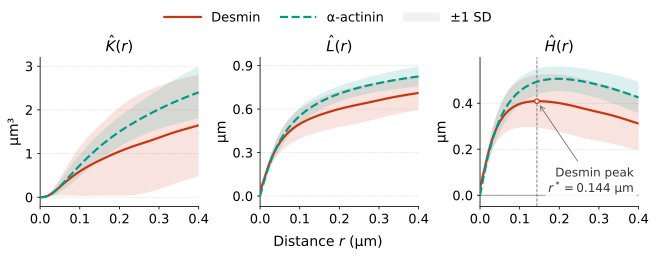

In [19]:
savepath = "../../figures/S4a"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)

In [20]:
fig, axes, info = plot_ripley_functions(
    "../../source_data/fig_s4/ripleys_actin.npz",
    proteins=("desmin", "actin"),
    figsize=(9, 3.5),

    line_width=2.2,
    band_alpha=0.14,
    title_fontsize=15,
    label_fontsize=14,
    tick_fontsize=13,
    legend_fontsize=13,

    # Set 2 or 3 to label K with the corresponding units.
    spatial_dimension=3,

    peak_protein="desmin",
    peak_text_position=(0.97, 0.08),  # Position within the H panel
    annotation_fontsize=12,
)


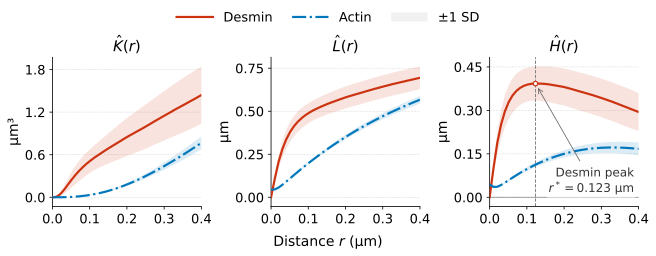

In [21]:
savepath = "../../figures/S4b"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)

In [26]:
fig, axes, info = plot_ripley_functions(
    series_sources=sources,

    labels={
        "actinin_dataset": "Desmin (α-actinin dataset)",
        "actin_dataset": "Desmin (actin dataset)",
    },
    linestyles={
        "actinin_dataset": "-",
        "actin_dataset": "-.",
    },

    figsize=(9, 3.5),
    line_width=2.2,
        band_alpha=0.14,
        title_fontsize=15,
        label_fontsize=14,
        tick_fontsize=13,
        legend_fontsize=13,
        spatial_dimension=3,
        
     
    peak_protein=None,  # Omit the peak annotation for this comparison.
)

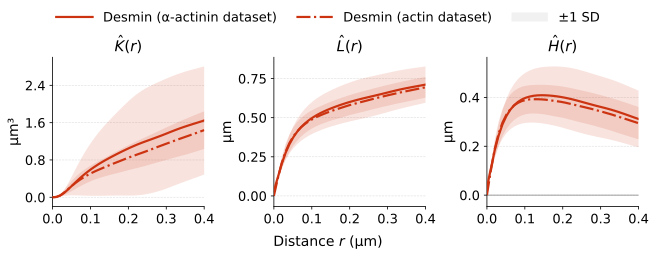

In [27]:
savepath = "../../figures/S4c"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)